# 02 – Exploration
Exploratory analysis of DE-LU day-ahead prices and covariate forecasts on the pre-test period (2023-01-01 → 2026-03-31).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src import config as cfg

df = pd.read_parquet(cfg.DATASET_PATH)
pre = df.loc[:"2026-03-31"]   # pre-test period only

print(pre.shape)
print(pre.index.min(), "→", pre.index.max())
pre.head()


(28464, 7)
2023-01-01 00:00:00 → 2026-03-31 23:00:00


,price,load_fc,wind_fc,solar_fc,hour,dow,non_working_day
datetime,,,,,,,
2023-01-01 00:00:00,-5.17,42.215472,39.002553,0.0,0,6,1
2023-01-01 01:00:00,-1.07,40.026935,38.805622,0.0,1,6,1
2023-01-01 02:00:00,-1.47,38.631030,38.542233,0.0,2,6,1
2023-01-01 03:00:00,-5.08,37.588662,37.858970,0.0,3,6,1
2023-01-01 04:00:00,-4.49,37.705735,37.336290,0.0,4,6,1


## 1. Series overview and descriptive statistics

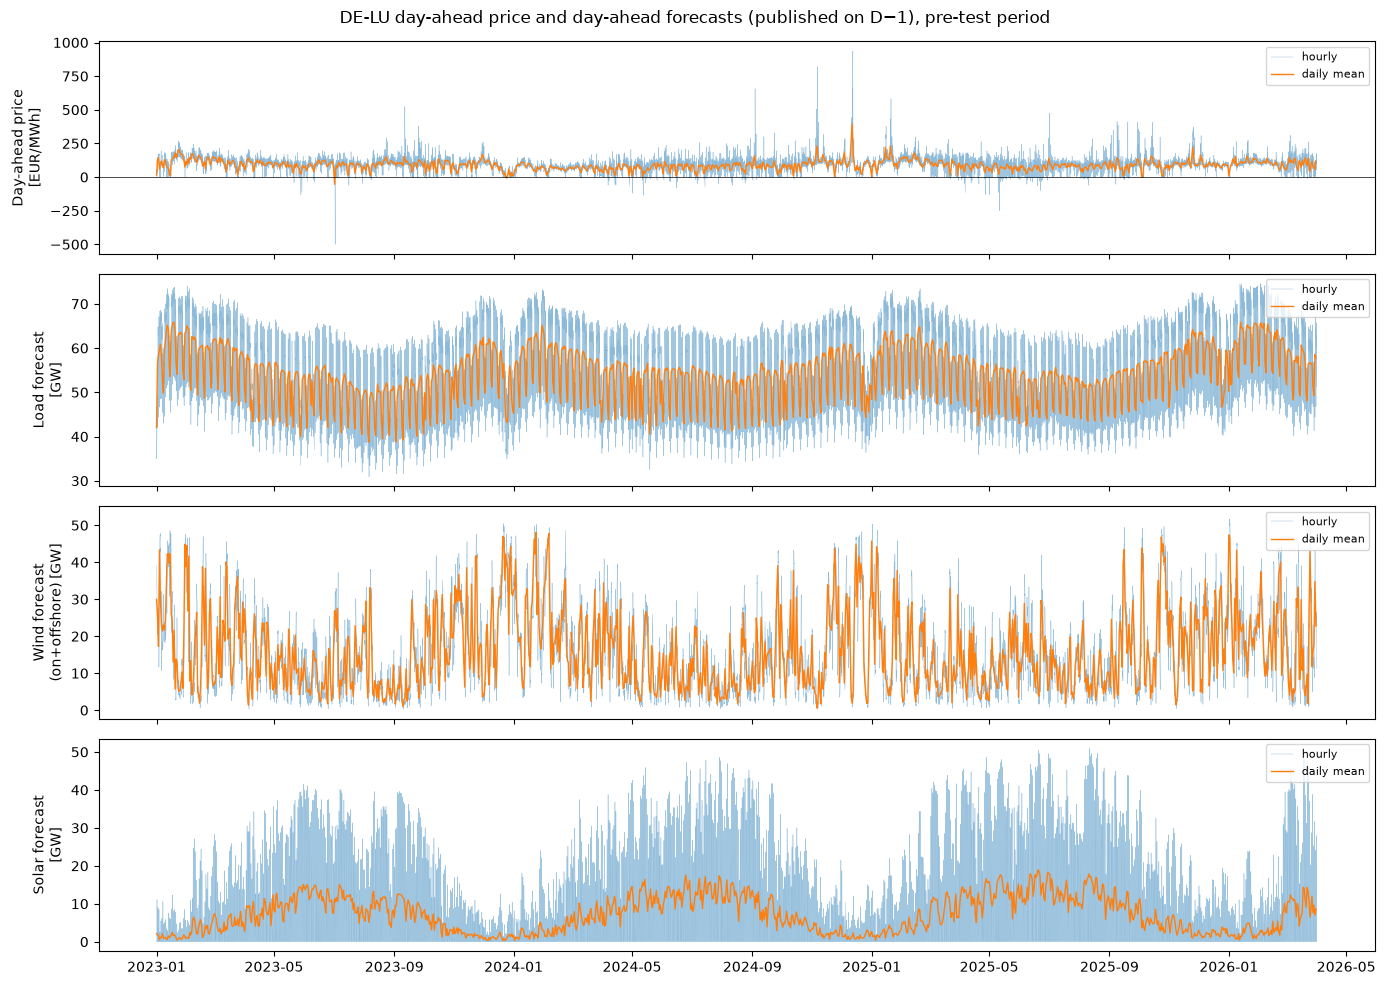

In [ ]:
cols = ["price", "load_fc", "wind_fc", "solar_fc"]
labels = {
    "price":    "Day-ahead price\n[EUR/MWh]",
    "load_fc":  "Load forecast\n[GW]",
    "wind_fc":  "Wind forecast\n(on+offshore) [GW]",
    "solar_fc": "Solar forecast\n[GW]",
}

fig, axes = plt.subplots(4, 1, sharex=True, figsize=(14, 10))

for ax, col in zip(axes, cols):
    ax.plot(pre.index, pre[col], lw=0.3, alpha=0.5, label="hourly")
    daily = pre[col].resample("D").mean()
    ax.plot(daily.index, daily, lw=1, color="C1", label="daily mean")
    ax.set_ylabel(labels[col])
    ax.legend(loc="upper right", fontsize=8)

axes[0].axhline(0, color="k", lw=0.5)   # zero line: makes negative prices visible
fig.suptitle("DE-LU day-ahead price and day-ahead forecasts (published on D−1), pre-test period")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "series_overview.png", dpi=150)
plt.show()

In [ ]:
pre[cols].describe().round(1)

,price,load_fc,wind_fc,solar_fc
count,28464.0,28464.0,28464.0,28464.0
mean,88.8,53.9,16.0,7.2
std,50.9,9.1,11.3,11.1
min,-500.0,30.9,0.2,0.0
25%,66.6,46.5,6.7,0.0
50%,91.3,53.7,13.4,0.2
75%,114.0,61.2,23.2,11.4
max,936.3,74.6,52.5,50.9


In [ ]:
p = pre["price"]

print(f"Min price: {p.min():.1f} EUR/MWh on {p.idxmin()}")
print(f"Max price: {p.max():.1f} EUR/MWh on {p.idxmax()}")

Min price: -500.0 EUR/MWh on 2023-07-02 14:00:00
Max price: 936.3 EUR/MWh on 2024-12-12 17:00:00


**Observations.**
- Most prices are between 67 and 114 EUR/MWh.
- But some prices are extreme: the lowest is −500 EUR/MWh (Sunday 2 July 2023, 14:00: lots of sun, low demand), the highest is 936 EUR/MWh (12 December 2024, 17:00: winter evening, almost no wind).
- Prices are calm in some periods and very unstable in others.
- Load is higher in winter and lower on weekends. Wind changes a lot from day to day. Solar is high in summer.

## 2. Daily and weekly profiles


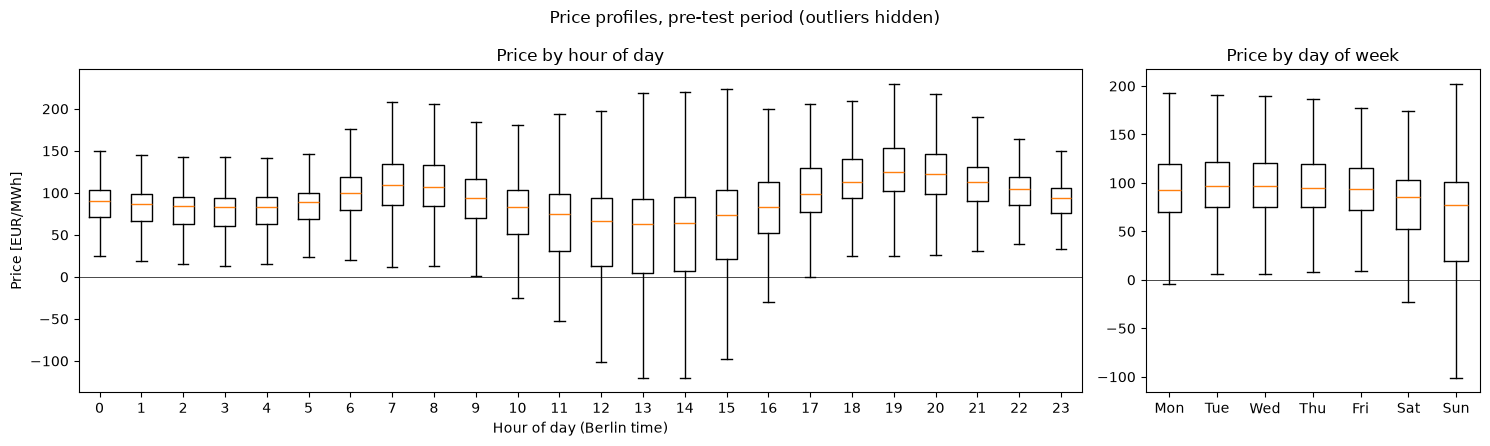

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 1]})

# Price distribution for each hour of the day
by_hour = [pre.loc[pre["hour"] == h, "price"] for h in range(24)]
axes[0].boxplot(by_hour, showfliers=False)
axes[0].set_xticks(range(1, 25), range(24))
axes[0].set_xlabel("Hour of day (Berlin time)")
axes[0].set_ylabel("Price [EUR/MWh]")
axes[0].set_title("Price by hour of day")

# Price distribution for each day of the week
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow = [pre.loc[pre["dow"] == d, "price"] for d in range(7)]
axes[1].boxplot(by_dow, showfliers=False)
axes[1].set_xticks(range(1, 8), days)
axes[1].set_title("Price by day of week")

for ax in axes:
    ax.axhline(0, color="k", lw=0.5)

fig.suptitle("Price profiles, pre-test period (outliers hidden)")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "price_profiles_boxplots.png", dpi=150)
plt.show()


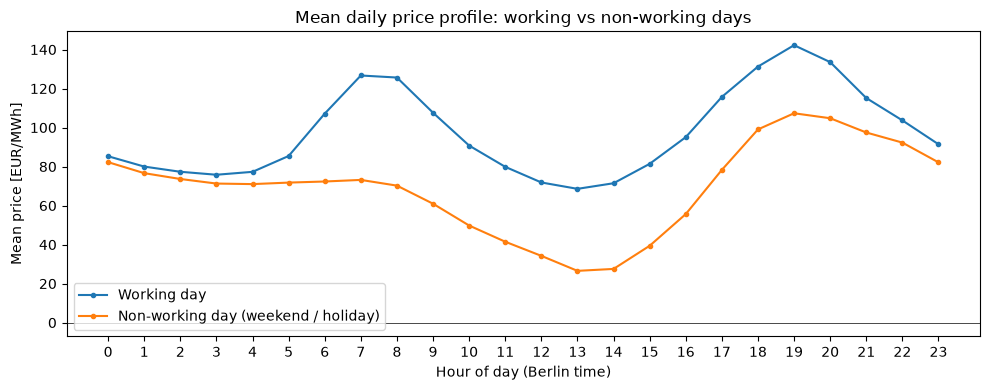

In [ ]:
profile = pre.groupby(["non_working_day", "hour"])["price"].mean().unstack(0)
profile.columns = ["Working day", "Non-working day (weekend / holiday)"]

ax = profile.plot(figsize=(10, 4), marker="o", ms=3)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Hour of day (Berlin time)")
ax.set_ylabel("Mean price [EUR/MWh]")
ax.set_title("Mean daily price profile: working vs non-working days")
ax.set_xticks(range(24))
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "profile_working_vs_nonworking.png", dpi=150)
plt.show()

**Observations.**
- Prices follow the same shape every day: high in the morning (7–8 h), low at midday (13–14 h, because of solar), highest in the evening (19–20 h).
- Prices vary most at midday, and this is also when most negative prices happen.
- Weekends are cheaper, especially Sunday.
- On weekends and holidays, there is no morning peak and midday prices are much lower.
- So the model needs a daily season (s = 24) and the `non_working_day` covariate.

## 3. Price distribution: heavy tails, negative prices and spikes

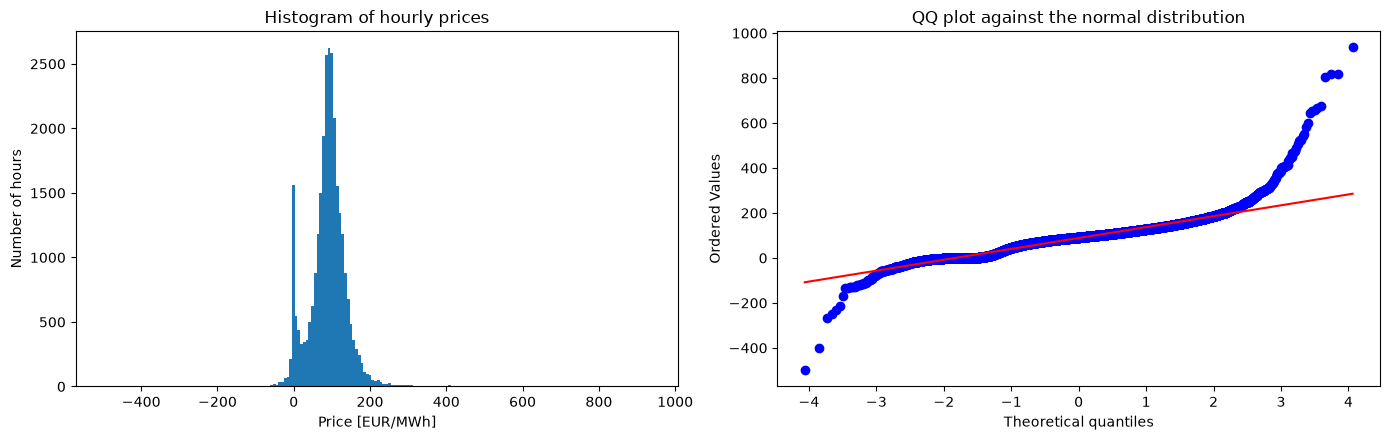

In [ ]:
import scipy.stats as stats

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(p, bins=200)
axes[0].set_xlabel("Price [EUR/MWh]")
axes[0].set_ylabel("Number of hours")
axes[0].set_title("Histogram of hourly prices")

# QQ plot: if prices were normal, the points would follow the red line
stats.probplot(p, dist="norm", plot=axes[1])
axes[1].set_title("QQ plot against the normal distribution")

fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "price_distribution.png", dpi=150)
plt.show()

In [ ]:
# Spike: price more than 3 standard deviations above the mean
spike_threshold = p.mean() + 3 * p.std()

print(f"Negative-price hours: {(p < 0).sum()} ({(p < 0).mean():.1%} of all hours)")
print(f"Spike hours (> {spike_threshold:.0f} EUR/MWh): {(p > spike_threshold).sum()} ({(p > spike_threshold).mean():.1%} of all hours)")

Negative-price hours: 1381 (4.9% of all hours)
Spike hours (> 241 EUR/MWh): 203 (0.7% of all hours)


**Observations.**
- Prices are not normally distributed: the QQ plot moves away from the line at both ends. Extreme prices are much more frequent than for a normal distribution ("heavy tails").
- About 5 % of hours have a negative price.
- Spikes (above ≈ 241 EUR/MWh) are rare: about 0.7 % of hours.
- We keep all these values: they are real.

## 4. Trend / season / noise decomposition

Additive decomposition (prices can be negative), with a period of 168 h (one week), so the season contains both the daily and the weekly cycle.

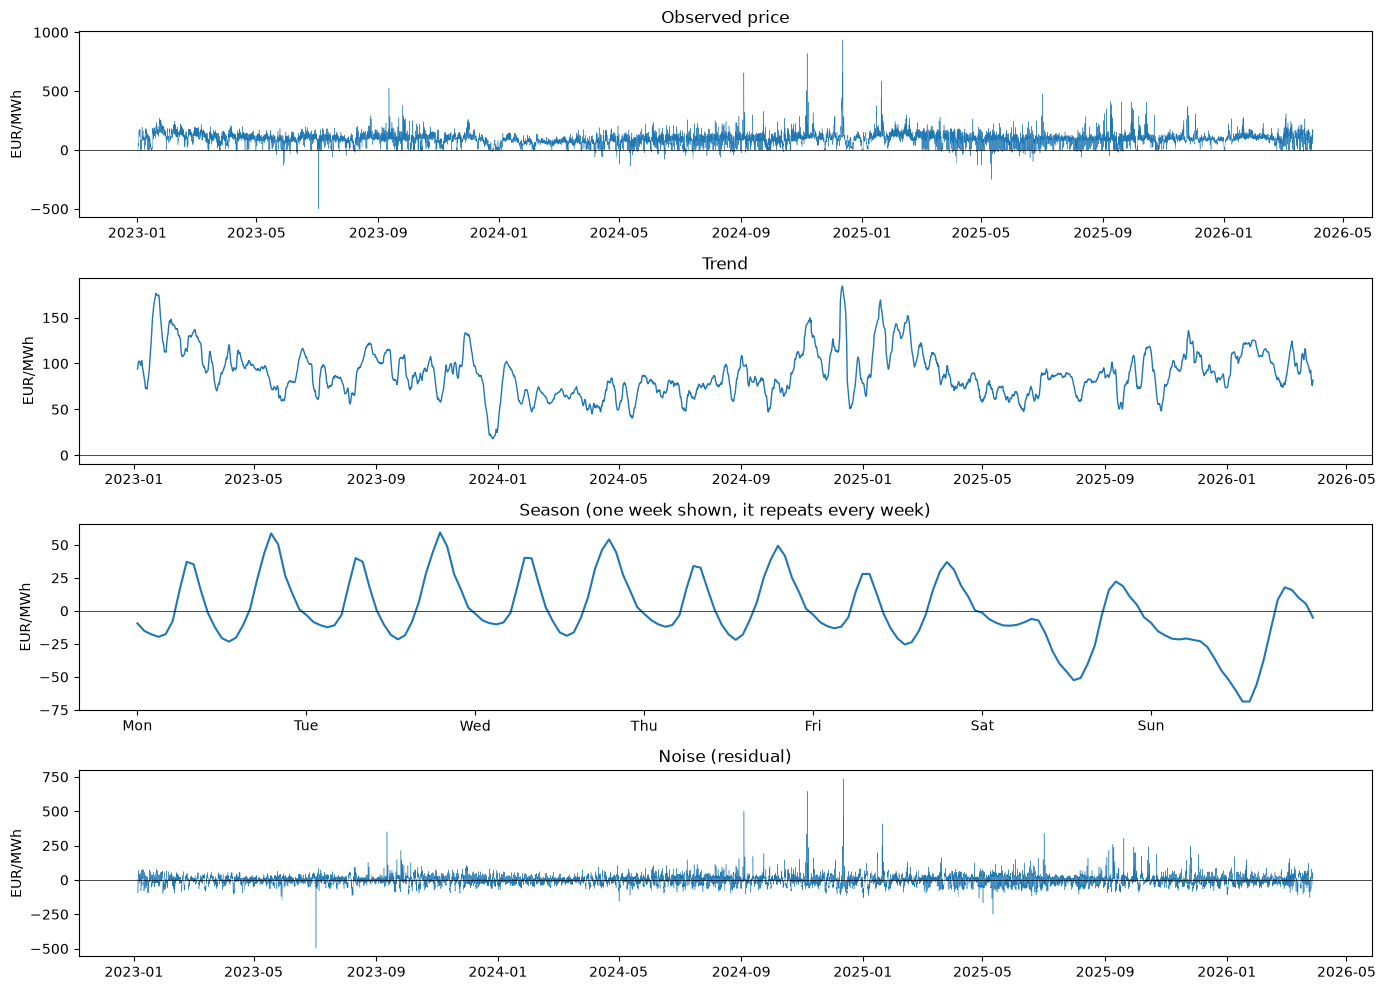

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(p, model="additive", period=168)

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

axes[0].plot(p, lw=0.3)
axes[0].set_title("Observed price")

axes[1].plot(decomp.trend, lw=1)
axes[1].set_title("Trend")

# The season repeats every week, so we show only one week (Monday to Sunday)
week = decomp.seasonal.loc["2023-01-02":"2023-01-08"]   # 2023-01-02 is a Monday
axes[2].plot(range(168), week.values)
axes[2].set_xticks(range(0, 168, 24), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[2].set_title("Season (one week shown, it repeats every week)")

axes[3].plot(decomp.resid, lw=0.3)
axes[3].set_title("Noise (residual)")

for ax in axes:
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("EUR/MWh")

fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "price_decomposition.png", dpi=150)
plt.show()

**Observations.**
- Trend: no clear long-term increase or decrease. The level moves between about 20 and 180 EUR/MWh, with the highest peaks in winter (e.g. December 2024).
- Season: the same weekly pattern repeats: two peaks per weekday (morning and evening), a midday dip, and much lower prices on Saturday and Sunday.
- Noise: large, and it contains all the spikes and negative prices. These are not explained by trend or season.

## 5. Autocorrelation and stationarity

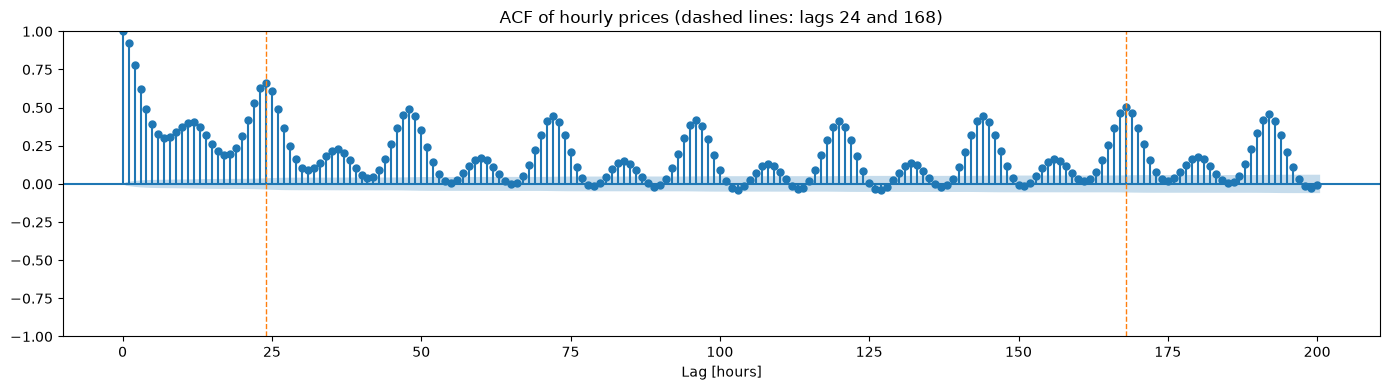

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(p, lags=200, ax=ax)
for lag in [24, 168]:
    ax.axvline(lag, color="C1", ls="--", lw=1)   # expected peaks: 1 day and 1 week
ax.set_xlabel("Lag [hours]")
ax.set_title("ACF of hourly prices (dashed lines: lags 24 and 168)")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "price_acf.png", dpi=150)
plt.show()

**Observations.**
- The ACF has a peak every 24 hours: the price at the same hour the day before is similar.
- The peak at lag 168 (one week) is higher than the peaks around it (144, 192): the same hour one week before is also similar.
- The seasonal peaks decrease very slowly: the season is strong and persistent.

**Stationarity** (weak stationarity: stable mean, stable variance, stable dependence):
- Mean: no long-term trend (see the decomposition), so the mean looks roughly stable.
- Variance: not stable. Some periods are calm, others have many spikes.
- Dependence: the strong seasonal peaks in the ACF show a periodic component.
- So the price series is not stationary as it is. The seasonal part must be removed (seasonal differencing) before fitting an ARMA-type model.

## 6. Price vs covariates

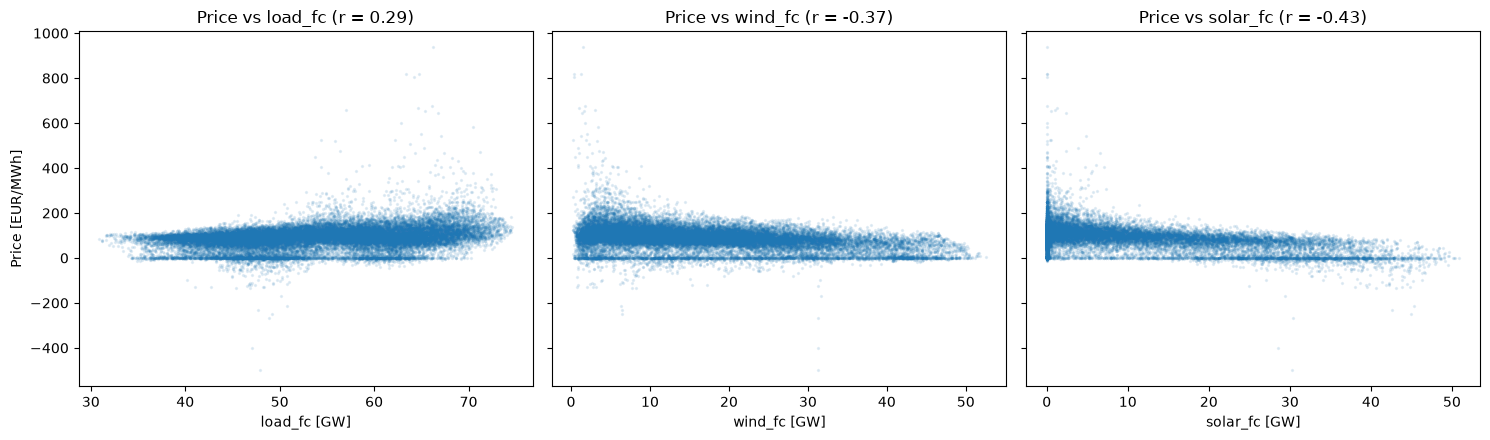

load_fc     0.29
wind_fc    -0.37
solar_fc   -0.43
dtype: float64

In [ ]:
covs = ["load_fc", "wind_fc", "solar_fc"]
corr = pre[covs].corrwith(p)   # Pearson correlation of each covariate with the price

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, col in zip(axes, covs):
    ax.scatter(pre[col], p, s=2, alpha=0.1)
    ax.set_xlabel(f"{col} [GW]")
    ax.set_title(f"Price vs {col} (r = {corr[col]:.2f})")
axes[0].set_ylabel("Price [EUR/MWh]")

fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "price_vs_covariates.png", dpi=150)
plt.show()

corr.round(2)

**Observations.**
- Higher load goes with higher prices (r = 0.29).
- More wind (r = −0.37) and more solar (r = −0.43) go with lower prices.
- The very high prices only happen when wind and solar are low.
- The correlations are moderate: no covariate alone explains the price.
- These are correlations only. They do not prove causality: for example, solar and load both follow the time of day, so part of the link can come from the daily cycle.

## 7. SARIMA order selection

Orders of the SARIMA model (lecture 4), chosen here **on the pre-test period only** (2023-01-01 → 2026-03-31) and then **frozen** in `src/config.py` for the whole test period. SARIMAX uses the same orders (CLAUDE.md section 6).

Fixed by the protocol, not selected here:
- season **s = 24** (daily cycle);
- the estimation window: the **last 8 weeks** (1,344 h), as in the rolling evaluation, where the model is refitted every Monday.

Course approach: (1) seasonal differencing (1−B²⁴); (2) ACF/PACF of the differenced series to propose orders; (3) fit a few candidates; (4) check the residuals (`plot_diagnostics`, Ljung-Box).

### 7.1 Seasonal differencing (1−B²⁴)

The differenced series is $y_t - y_{t-24}$: the price minus the price at the same hour the day before. It removes the daily cycle and the slow changes of level.

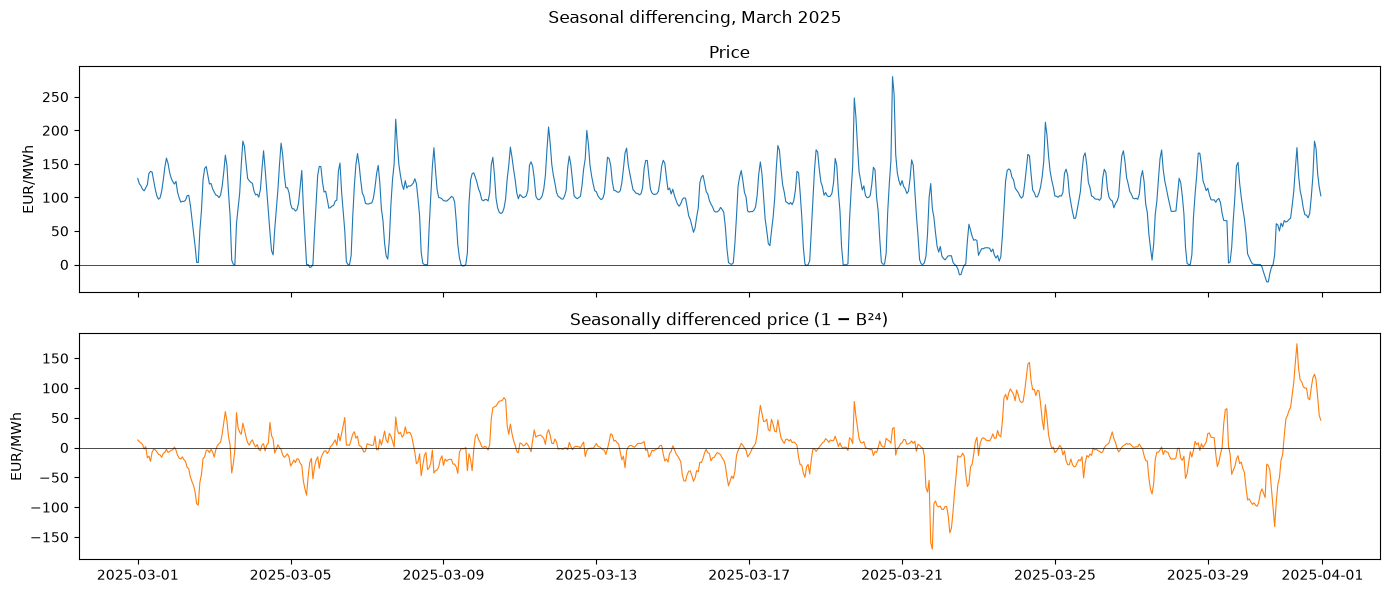

Standard deviation: price 50.9, differenced 41.6 EUR/MWh


In [ ]:
y_pre = p.asfreq("h")          # pre-test prices, hourly frequency (statsmodels expects it)
d24 = y_pre.diff(24).dropna()   # (1 − B^24) y_t = y_t − y_{t−24}

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
month = slice("2025-03-01", "2025-03-31")   # one month, so that the hours are visible
axes[0].plot(y_pre.loc[month], lw=0.8)
axes[0].set_title("Price")
axes[1].plot(d24.loc[month], lw=0.8, color="C1")
axes[1].set_title("Seasonally differenced price (1 − B²⁴)")
for ax in axes:
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("EUR/MWh")
fig.suptitle("Seasonal differencing, March 2025")
fig.tight_layout()
plt.show()

print(f"Standard deviation: price {y_pre.std():.1f}, differenced {d24.std():.1f} EUR/MWh")

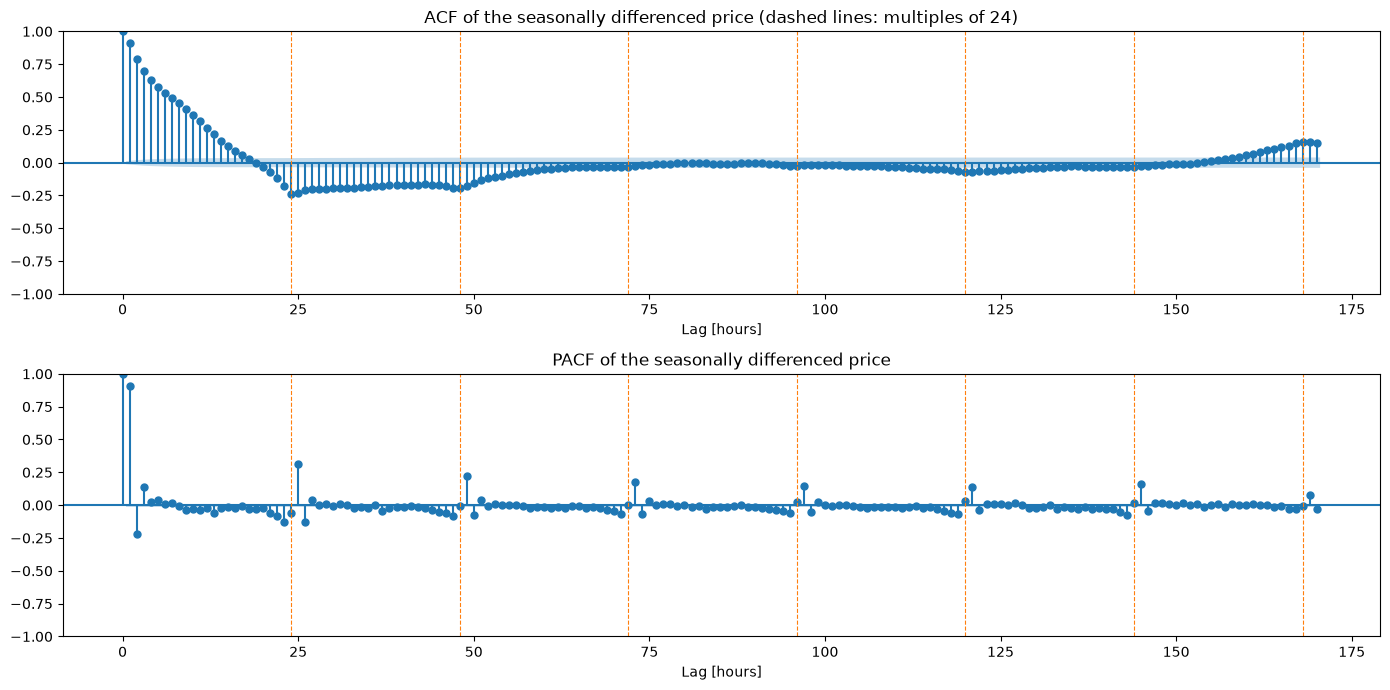

lag,1,2,3,4,5,12,24,25,48,49,72,168
ACF,0.91,0.79,0.70,0.63,0.58,0.27,-0.24,-0.23,-0.19,-0.18,-0.03,0.16
PACF,0.91,-0.22,0.14,0.02,0.04,-0.03,-0.06,0.31,-0.00,0.22,0.00,-0.01


In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(d24, lags=170, ax=axes[0])
plot_pacf(d24, lags=170, ax=axes[1], method="ywm")
for ax in axes:
    for lag in [24, 48, 72, 96, 120, 144, 168]:
        ax.axvline(lag, color="C1", ls="--", lw=0.8)   # seasonal lags (multiples of 24)
    ax.set_xlabel("Lag [hours]")
axes[0].set_title("ACF of the seasonally differenced price (dashed lines: multiples of 24)")
axes[1].set_title("PACF of the seasonally differenced price")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "sarima_acf_pacf_diff24.png", dpi=150)
plt.show()

from statsmodels.tsa.stattools import acf, pacf

lags = [1, 2, 3, 4, 5, 12, 24, 25, 48, 49, 72, 168]
pd.DataFrame({"ACF": acf(d24, nlags=168)[lags], "PACF": pacf(d24, nlags=168, method="ywm")[lags]}, index=pd.Index(lags, name="lag")).round(2).T

**Observations.**
- The differenced series varies around 0: the daily cycle and the slow changes of level are removed. Its variance is still not constant (calm and turbulent periods), and the standard deviation only drops from 50.9 to 41.6 EUR/MWh.
- **Non-seasonal part**: the ACF decays slowly and smoothly (0.91, 0.79, 0.70 …, close to 0 after about 20 h), while the PACF has one large spike at lag 1 (0.91), smaller ones at lags 2 (−0.22) and 3 (0.14), and almost nothing after. This is an AR pattern: AR(1), possibly up to AR(3). An MA(1) term can absorb the small extra lags with fewer parameters. Candidates: (1,0,0), (2,0,0), (3,0,0), (1,0,1), (2,0,1).
- No extra non-seasonal difference: the ACF reaches 0 within about one day, so **d = 0**.
- **Seasonal part**: negative ACF at lag 24 (−0.24), and a PACF that decays along the seasonal lags (lag 25: 0.31, 49: 0.22, 73: 0.18 …). This is the usual signature of a **seasonal MA(1)** after a seasonal difference: **D = 1, Q = 1**. A seasonal AR term (P = 1), as in the suggested starting point, is also tested.
- **Weekly structure left**: the ACF rises again towards lag 168 (0.16). A daily season s = 24 cannot model it; SARIMAX gets part of it through `non_working_day`.

### 7.2 Candidate orders on 8-week windows

Candidates: the orders suggested by the ACF/PACF, around the suggested starting point (1,0,1)(1,1,1)₂₄. Always d = 0 and D = 1 (one seasonal difference, no constant).

Each candidate is fitted on **21 non-overlapping 8-week windows** that tile the pre-test period (Monday 2 January 2023 → Sunday 22 March 2026), with `statsmodels.tsa.statespace.sarimax.SARIMAX`, as in the course. This is the same window length as in the rolling evaluation, and the windows cover all seasons.

For each window and candidate:
- **AIC** and **BIC** (lower is better; BIC penalises the number of parameters more);
- **Ljung-Box** test on the residuals at lags 24 and 48 (H₀: no autocorrelation; `model_df` = number of ARMA parameters). The first residuals, used to initialise the seasonal difference (`loglikelihood_burn`), are dropped;
- a secondary check, **still inside the pre-test period**: MAE of the 24-hour forecasts of the 7 days that follow the window (Monday → Sunday). As in the rolling evaluation, the model is fitted on Monday and the next days only add the new prices to the model state, without re-estimating the parameters (`results.append(..., refit=False)`). The reference naive is computed on the same days for scale.

Takes ≈ 20 minutes on CPU (147 fits); the table is cached in `results/sarima_order_selection.parquet` (not versioned) and reloaded on the next run.

In [ ]:
import time
import warnings

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

ONE_HOUR = pd.Timedelta(hours=1)

# (p, d, q), (P, D, Q): d = 0, D = 1 for all candidates
candidates = {
    "(1,0,0)(0,1,1)": ((1, 0, 0), (0, 1, 1)),
    "(2,0,0)(0,1,1)": ((2, 0, 0), (0, 1, 1)),
    "(3,0,0)(0,1,1)": ((3, 0, 0), (0, 1, 1)),
    "(1,0,1)(0,1,1)": ((1, 0, 1), (0, 1, 1)),
    "(2,0,1)(0,1,1)": ((2, 0, 1), (0, 1, 1)),
    "(1,0,1)(1,1,1)": ((1, 0, 1), (1, 1, 1)),   # suggested starting point
    "(2,0,1)(1,1,1)": ((2, 0, 1), (1, 1, 1)),
}

# Monday after each window (fit day). The 7 forecast days must stay inside the pre-test period.
fit_days = pd.date_range("2023-02-27", cfg.PRETEST_END - pd.Timedelta(days=6), freq="56D")
assert len(fit_days) == 21 and (fit_days.day_of_week == 0).all()
assert fit_days[0] - pd.Timedelta(hours=cfg.FIT_WINDOW_HOURS) >= y_pre.index[0]
assert fit_days[-1] + pd.Timedelta(days=7) - ONE_HOUR <= y_pre.index[-1]   # no data after 2026-03-31


def reference_naive(day):
    # D−7 on Monday, Saturday, Sunday, D−1 otherwise (src.baselines.NaiveReference)
    lag = 7 if day.day_of_week in (0, 5, 6) else 1
    return y_pre.loc[day - pd.Timedelta(days=lag) : day - pd.Timedelta(days=lag) + 23 * ONE_HOUR].to_numpy()


SELECTION_PATH = cfg.RESULTS_DIR / "sarima_order_selection.parquet"   # cache (not versioned)

rows = []
start = time.perf_counter()
for fit_day in ([] if SELECTION_PATH.exists() else fit_days):
    y = y_pre.loc[fit_day - pd.Timedelta(hours=cfg.FIT_WINDOW_HOURS) : fit_day - ONE_HOUR]
    assert len(y) == cfg.FIT_WINDOW_HOURS
    week = [fit_day + pd.Timedelta(days=k) for k in range(7)]
    actual = [y_pre.loc[day : day + 23 * ONE_HOUR].to_numpy() for day in week]
    naive_mae = np.mean([np.abs(a - reference_naive(day)) for a, day in zip(actual, week)])

    for name, (order, seasonal) in candidates.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            res = SARIMAX(y, order=order, seasonal_order=(*seasonal, cfg.SARIMA_SEASON)).fit(disp=False)
        n_arma = order[0] + order[2] + seasonal[0] + seasonal[2]
        lb = acorr_ljungbox(res.resid.iloc[res.loglikelihood_burn :], lags=[24, 48], model_df=n_arma)

        errors = []
        for k, day in enumerate(week):
            # Monday: fitted model; other days: append the prices up to D−1, same parameters
            res_day = res if k == 0 else res.append(y_pre.loc[fit_day : day - ONE_HOUR], refit=False)
            errors.append(np.abs(actual[k] - res_day.forecast(24).to_numpy()))

        rows.append({
            "fit_day": fit_day, "model": name, "n_params": n_arma, "aic": res.aic, "bic": res.bic,
            "converged": res.mle_retvals["converged"], "n_warnings": len(caught),
            "lb_p24": lb["lb_pvalue"].iloc[0], "lb_p48": lb["lb_pvalue"].iloc[1],
            "mae_week": np.mean(errors), "mae_naive_ref": naive_mae,
        })
    print(f"{fit_day.date()} done ({time.perf_counter() - start:.0f} s)")

if SELECTION_PATH.exists():
    selection = pd.read_parquet(SELECTION_PATH)
    print(f"Loaded from {SELECTION_PATH.relative_to(cfg.ROOT)}")
else:
    selection = pd.DataFrame(rows)
    selection.to_parquet(SELECTION_PATH, index=False)
assert set(selection["model"]) == set(candidates) and (pd.DatetimeIndex(selection["fit_day"].unique()) == fit_days).all()

2023-02-27 done (53 s)


2023-04-24 done (102 s)


2023-06-19 done (155 s)


2023-08-14 done (223 s)


2023-10-09 done (284 s)


2023-12-04 done (338 s)


... (11 outputs left out)

2025-10-06 done (1043 s)


2025-12-01 done (1092 s)


2026-01-26 done (1145 s)


2026-03-23 done (1188 s)


In [ ]:
selection["aic_rank"] = selection.groupby("fit_day")["aic"].rank()
selection["bic_rank"] = selection.groupby("fit_day")["bic"].rank()
selection["rmae_week"] = selection["mae_week"] / selection["mae_naive_ref"]

summary = selection.groupby("model").agg(
    n_params=("n_params", "first"),
    converged=("converged", "mean"),
    n_warnings=("n_warnings", "sum"),
    mean_aic=("aic", "mean"),
    mean_aic_rank=("aic_rank", "mean"),
    mean_bic=("bic", "mean"),
    mean_bic_rank=("bic_rank", "mean"),
    share_lb24_ok=("lb_p24", lambda s: (s > 0.05).mean()),   # windows where Ljung-Box does not reject at 5 %
    median_lb_p24=("lb_p24", "median"),
    mae_week=("mae_week", "mean"),
).loc[list(candidates)]

print(f"Reference naive MAE on the same 147 days: {selection.groupby('fit_day')['mae_naive_ref'].first().mean():.2f} EUR/MWh")
summary.round(3)

Reference naive MAE on the same 147 days: 27.53 EUR/MWh


,n_params,converged,n_warnings,mean_aic,mean_aic_rank,mean_bic,mean_bic_rank,share_lb24_ok,median_lb_p24,mae_week
model,,,,,,,,,,
"(1,0,0)(0,1,1)",2,1.000,0,10454.495,7.000,10470.051,7.000,0.000,0.0,21.963
"(2,0,0)(0,1,1)",3,1.000,0,10350.661,5.429,10371.402,4.810,0.000,0.0,22.911
"(3,0,0)(0,1,1)",4,1.000,0,10317.750,2.952,10343.677,3.238,0.048,0.0,22.207
"(1,0,1)(0,1,1)",3,1.000,0,10333.100,4.714,10353.841,3.857,0.000,0.0,22.668
"(2,0,1)(0,1,1)",4,1.000,7,10326.075,3.905,10352.002,4.381,0.000,0.0,22.696
"(1,0,1)(1,1,1)",4,1.000,0,10298.878,2.286,10324.805,2.143,0.000,0.0,22.139
"(2,0,1)(1,1,1)",5,0.952,8,10292.096,1.714,10323.208,2.571,0.048,0.0,22.140


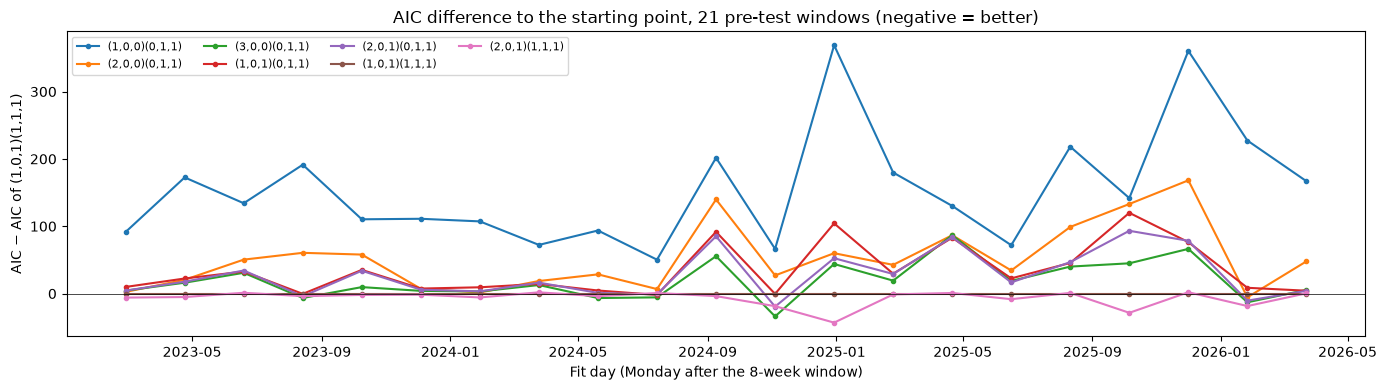

In [ ]:
# AIC of each candidate minus the AIC of the starting point (1,0,1)(1,1,1), window by window
delta = selection.pivot(index="fit_day", columns="model", values="aic")[list(candidates)]
delta = delta.sub(delta["(1,0,1)(1,1,1)"], axis=0)

fig, ax = plt.subplots(figsize=(14, 4))
for name in candidates:
    ax.plot(delta.index, delta[name], marker="o", ms=3, label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("AIC − AIC of (1,0,1)(1,1,1)")
ax.set_xlabel("Fit day (Monday after the 8-week window)")
ax.set_title("AIC difference to the starting point, 21 pre-test windows (negative = better)")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**Observations.**
- **AIC / BIC**: the two candidates with a seasonal AR term, (1,0,1)(1,1,1) and (2,0,1)(1,1,1), are the best. The pure AR(1) model is clearly the worst (AIC +156 on average compared with the starting point).
- (2,0,1)(1,1,1) has a slightly lower AIC than (1,0,1)(1,1,1) (−6.8 on average, median −3.8, on values around 10,300) and a similar mean BIC (10,323 vs 10,325). (1,0,1)(1,1,1) has the best mean BIC rank (2.14 vs 2.57). But (2,0,1)(1,1,1) is **less stable**: the optimiser did not converge on 1 of the 21 windows (January 2024, with the seasonal MA coefficient at −0.999, on the invertibility boundary), and it raised estimation warnings (non-stationary or non-invertible starting parameters) on 4 other windows. Only the two (2,0,1) candidates raised warnings.
- **Ljung-Box**: at lag 24, H₀ (no autocorrelation) is rejected at 5 % on almost every window for every candidate (at most 1 window out of 21 passes). No candidate makes the residuals white noise. With 1,344 observations the test detects even small autocorrelations, and the residuals still contain structure that a low-order SARIMA with s = 24 cannot capture (weekly cycle, changing variance, spikes). The test does not separate the candidates.
- **Week-ahead forecasts** (147 pre-test days): all candidates are between 22.0 and 22.9 EUR/MWh MAE, against 27.5 for the reference naive (rMAE ≈ 0.85). The differences between candidates are below 1 EUR/MWh and do not follow the AIC ranking: (1,0,0)(0,1,1) has the lowest MAE but the worst AIC. Over 21 weeks, these differences are noise: forecast accuracy does not favour a more complex order.

### 7.3 Residual diagnostics of the selected order

Last pre-test window (Monday 26 January → Sunday 22 March 2026, 8 weeks), fitted with the selected order.

In [ ]:
last_window = y_pre.loc[fit_days[-1] - pd.Timedelta(hours=cfg.FIT_WINDOW_HOURS) : fit_days[-1] - ONE_HOUR]
res = SARIMAX(last_window, order=cfg.SARIMA_ORDER, seasonal_order=cfg.SARIMA_SEASONAL_ORDER).fit(disp=False)
print(res.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              price   No. Observations:                 1344
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood               -4866.233
Date:                            Thu, 19 Nov 2026   AIC                           9742.465
Time:                                    10:19:12   BIC                           9768.392
Sample:                                01-26-2026   HQIC                          9752.186
                                     - 03-22-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8986      0.008    117.012      0.000       0.884       0.914
ma.L1          0.4028      0.019   

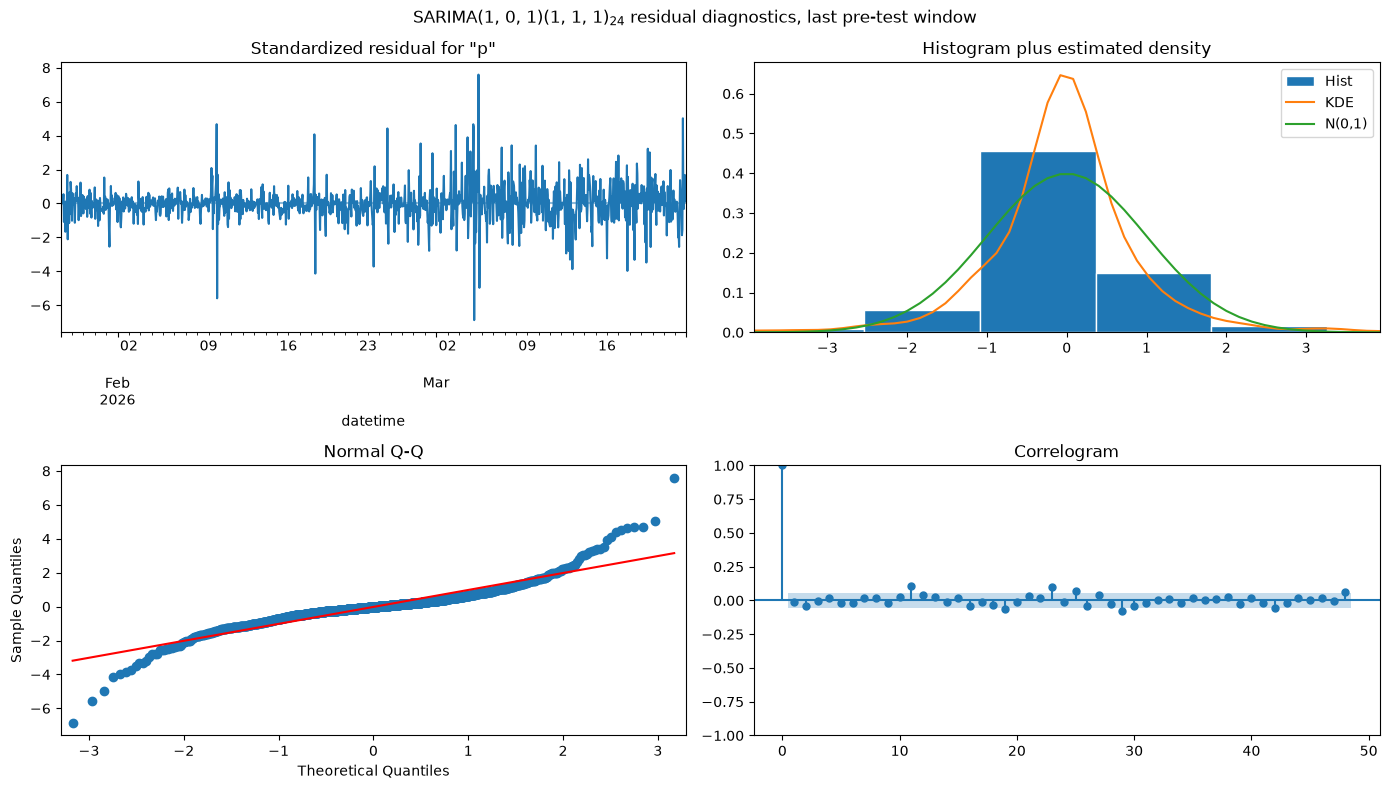

,lb_stat,lb_pvalue
24,47.8166,0.0005
48,82.5267,0.0004
168,217.6664,0.0032


In [ ]:
fig = res.plot_diagnostics(figsize=(14, 8), lags=48)
fig.suptitle(f"SARIMA{cfg.SARIMA_ORDER}{cfg.SARIMA_SEASONAL_ORDER[:3]}$_{{24}}$ residual diagnostics, last pre-test window")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "sarima_residual_diagnostics.png", dpi=150)
plt.show()

resid = res.resid.iloc[res.loglikelihood_burn :]
n_arma = sum(cfg.SARIMA_ORDER[::2]) + cfg.SARIMA_SEASONAL_ORDER[0] + cfg.SARIMA_SEASONAL_ORDER[2]
acorr_ljungbox(resid, lags=[24, 48, 168], model_df=n_arma).round(4)

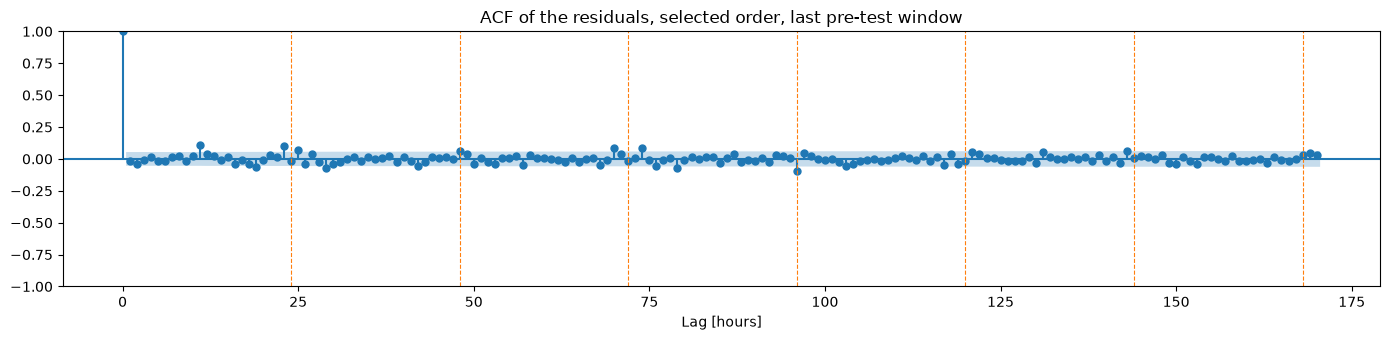

In [ ]:
fig, ax = plt.subplots(figsize=(14, 3.5))
plot_acf(resid, lags=170, ax=ax)
for lag in [24, 48, 72, 96, 120, 144, 168]:
    ax.axvline(lag, color="C1", ls="--", lw=0.8)
ax.set_xlabel("Lag [hours]")
ax.set_title("ACF of the residuals, selected order, last pre-test window")
fig.tight_layout()
plt.show()

**Observations.**
- All four coefficients are significant: ar.L1 = 0.90, ma.L1 = 0.40, ma.S.L24 = −0.82, and a small but significant seasonal AR (ar.S.L24 = 0.09, p = 0.001).
- **Correlogram**: the residual autocorrelations stay inside or close to the confidence band at almost all lags (largest ≈ ±0.1, at lags 11, 23 and 96). There is no strong peak left at the seasonal lags. Ljung-Box still rejects at lags 24, 48 and 168 (p < 0.01): the leftover autocorrelation is small, but with 1,344 observations it is significant.
- **Not normal**: the Q-Q plot moves away from the line at both ends (kurtosis 11.6, Jarque-Bera rejects normality), with residuals of 4 to 7 standard deviations. These are the price spikes.
- **Changing variance**: the heteroskedasticity test rejects (H = 3.63): the residuals are much larger in March than in February. The Gaussian prediction intervals of SARIMA are too narrow in turbulent periods. This affects intervals more than point forecasts (evaluated with MAE). Modelling it would need a GARCH-type model (later in the course).

### 7.4 Choice and frozen orders

**Selected order: SARIMA(1,0,1)(1,1,1)₂₄**, the suggested starting point.

Reasons:
1. **Matches the ACF/PACF** of the differenced series: AR(1) + MA(1) for the short lags, a seasonal MA(1) after the seasonal difference, and a small seasonal AR term (significant).
2. **Information criteria**: best mean BIC rank and second-best AIC. The only candidate with a lower AIC, (2,0,1)(1,1,1), gains little (median −3.8 AIC points) for one extra parameter.
3. **Stable estimation**: converged on all 21 windows, without warnings. In the rolling evaluation the model is refitted every Monday without supervision (26 refits on the main test, plus the control period), so a robust fit matters more than a small AIC gain. (2,0,1)(1,1,1) failed to converge once and raised warnings on 5 windows out of 21.
4. **Forecast accuracy** in the pre-test is the same for all candidates (within 1 EUR/MWh), so it does not justify a more complex order.

**Accepted limitation**: Ljung-Box rejects white-noise residuals for all candidates, and the residuals have heavy tails and a changing variance. A different order does not fix this: it comes from the weekly cycle (s = 24 only), from the spikes and from volatility clustering.

The orders are **frozen** in `src/config.py` and are not changed after this point. SARIMAX (`04_sarima.ipynb`) uses the same orders with the exogenous variables `load_fc`, `wind_fc`, `solar_fc`, `non_working_day`.

In [ ]:
# Frozen orders, read by 04_sarima.ipynb for SARIMA and SARIMAX
print("SARIMA_ORDER =", cfg.SARIMA_ORDER)
print("SARIMA_SEASONAL_ORDER =", cfg.SARIMA_SEASONAL_ORDER)
assert cfg.SARIMA_SEASONAL_ORDER[3] == cfg.SARIMA_SEASON == 24

SARIMA_ORDER = (1, 0, 1)
SARIMA_SEASONAL_ORDER = (1, 1, 1, 24)
